# Analisis Risiko Lingkungan dan Prediksi Anomali Suhu Surface Sea Temperature (SST) Serta Kualitas Udara Pesisir Sulawesi Tenggara

- **Nama :** Syakila Meilana Ruslin 
- **NIM :** E1E124018 
- **Mata Kuliah :** Data Science

# Menentukan Pertanyaan Bisnis 

1. Bagaimana tren suhu permukaan laut (SST), tinggi gelombang, dan kualitas udara (PM2.5/PM10) di wilayah pesisir Sulawesi Tenggara selama periode pengamatan?
2. Apakah terdapat korelasi signifikan antara anomali SST/gelombang tinggi dengan penurunan kualitas udara di wilayah pesisir?
3. Wilayah mana (Kendari, Kolaka, atau Konawe Selatan) yang memiliki tingkat risiko lingkungan pesisir tertinggi berdasarkan kombinasi ketiga variabel?
4. Bagaimana prediksi kondisi lingkungan pesisir (anomali SST) untuk beberapa hari ke depan menggunakan model machine learning?


# Import Semua Library/Packages yang Digunakan

In [2]:
# ===== Library untuk manipulasi data =====
import pandas as pd
import numpy as np

# ===== Library untuk koneksi ke database MySQL =====
import mysql.connector

# ===== Library untuk visualisasi =====
import matplotlib.pyplot as plt
import seaborn as sns

# ===== Library untuk uji statistik (korelasi) =====
from scipy import stats

# ===== Library untuk machine learning =====
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

# ===== Pengaturan tampilan =====
pd.set_option("display.max_columns", None)  # supaya semua kolom tampil, tidak terpotong
plt.rcParams["figure.figsize"] = (12, 5)     # ukuran default untuk semua grafik

# Data Wrangling

Gathering Data

In [3]:
DB_CONFIG = {
    "host": "localhost",
    "port": 3306,
    "user": "root",
    "password": "root",
    "database": "lingkungan_pesisir",
}

koneksi = mysql.connector.connect(**DB_CONFIG)

df_marine = pd.read_sql("SELECT * FROM tabel_oseanografi", koneksi)
df_cuaca = pd.read_sql("SELECT * FROM tabel_cuaca", koneksi)
df_udara = pd.read_sql("SELECT * FROM tabel_kualitas_udara", koneksi)

koneksi.close()

print(f"Oseanografi: {df_marine.shape}")
print(f"Cuaca: {df_cuaca.shape}")
print(f"Kualitas Udara: {df_udara.shape}")

C:\Users\MyBook PRO K7\AppData\Local\Temp\ipykernel_8348\1318805901.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_marine = pd.read_sql("SELECT * FROM tabel_oseanografi", koneksi)
C:\Users\MyBook PRO K7\AppData\Local\Temp\ipykernel_8348\1318805901.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cuaca = pd.read_sql("SELECT * FROM tabel_cuaca", koneksi)


Oseanografi: (19656, 4)
Cuaca: (19656, 4)
Kualitas Udara: (19656, 4)


C:\Users\MyBook PRO K7\AppData\Local\Temp\ipykernel_8348\1318805901.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_udara = pd.read_sql("SELECT * FROM tabel_kualitas_udara", koneksi)


In [4]:
df_marine.head()

,waktu,wilayah,sea_surface_temperature,wave_height
0,2026-01-01 00:00:00,Kendari,30.4,0.06
1,2026-01-01 00:00:00,Kolaka,30.9,0.08
2,2026-01-01 00:00:00,Konawe Selatan,31.0,0.02
3,2026-01-01 01:00:00,Kendari,30.4,0.04
4,2026-01-01 01:00:00,Kolaka,30.8,0.08


In [5]:
df_cuaca.head()

,waktu,wilayah,precipitation,windspeed_10m
0,2026-01-01 00:00:00,Kendari,0.0,5.1
1,2026-01-01 00:00:00,Kolaka,0.0,4.0
2,2026-01-01 00:00:00,Konawe Selatan,0.6,1.5
3,2026-01-01 01:00:00,Kendari,0.0,5.5
4,2026-01-01 01:00:00,Kolaka,0.0,3.6


In [6]:
df_udara.head()

,waktu,wilayah,pm2_5,pm10
0,2026-01-01 00:00:00,Kendari,28.5,28.7
1,2026-01-01 00:00:00,Kolaka,13.7,13.9
2,2026-01-01 00:00:00,Konawe Selatan,25.4,25.6
3,2026-01-01 01:00:00,Kendari,29.9,30.2
4,2026-01-01 01:00:00,Kolaka,12.0,12.3


### Insight:

- Kolom `waktu` telah dikenali sebagai *datetime* dari awal setelah data ditarik.
- Karena ketiga tabel ditarik dari API yang berbeda (Marine, Weather, Air Quality) secara terpisah, terdapat kemungkinan ada baris waktu yang tidak sepenuhnya selaras antar tabel (misalnya satu sumber API sempat gagal merespons di jam tertentu), hal ini perlu diverifikasi pada tahap *Assessing Data* sebelum proses *join*.
- Granularitas data per jam menghasilkan volume data yang cukup besar (ribuan baris per wilayah), sehingga pengecekan *missing value* dan duplikasi data menjadi krusial sebelum data digunakan pada tahap analisis dan pemodelan berikutnya.

Assesing Data

In [7]:
print("=== Info Tabel Oseanografi ===")
df_marine.info()
print("\n=== Info Tabel Cuaca ===")
df_cuaca.info()
print("\n=== Info Tabel Kualitas Udara ===")
df_udara.info()

=== Info Tabel Oseanografi ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19656 entries, 0 to 19655
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   waktu                    19656 non-null  datetime64[ns]
 1   wilayah                  19656 non-null  object        
 2   sea_surface_temperature  19656 non-null  float64       
 3   wave_height              19656 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 614.4+ KB

=== Info Tabel Cuaca ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19656 entries, 0 to 19655
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   waktu          19656 non-null  datetime64[ns]
 1   wilayah        19656 non-null  object        
 2   precipitation  19656 non-null  float64       
 3   windspeed_10m  19656 non-nul

In [8]:
print("=== Missing Value - Oseanografi ===")
print(df_marine.isnull().sum())
print("\n=== Missing Value - Cuaca ===")
print(df_cuaca.isnull().sum())
print("\n=== Missing Value - Kualitas Udara ===")
print(df_udara.isnull().sum())

=== Missing Value - Oseanografi ===
waktu                      0
wilayah                    0
sea_surface_temperature    0
wave_height                0
dtype: int64

=== Missing Value - Cuaca ===
waktu            0
wilayah          0
precipitation    0
windspeed_10m    0
dtype: int64

=== Missing Value - Kualitas Udara ===
waktu      0
wilayah    0
pm2_5      0
pm10       0
dtype: int64


In [9]:
print("Duplikat - Oseanografi:", df_marine.duplicated(subset=["waktu", "wilayah"]).sum())
print("Duplikat - Cuaca:", df_cuaca.duplicated(subset=["waktu", "wilayah"]).sum())
print("Duplikat - Kualitas Udara:", df_udara.duplicated(subset=["waktu", "wilayah"]).sum())

Duplikat - Oseanografi: 0
Duplikat - Cuaca: 0
Duplikat - Kualitas Udara: 0


In [10]:
print("=== Statistik Deskriptif - Oseanografi ===")
display(df_marine.describe())
print("\n=== Statistik Deskriptif - Cuaca ===")
display(df_cuaca.describe())
print("\n=== Statistik Deskriptif - Kualitas Udara ===")
display(df_udara.describe())

=== Statistik Deskriptif - Oseanografi ===


,waktu,sea_surface_temperature,wave_height
count,19656,19656.000000,19656.000000
mean,2026-05-17 12:43:50.769230592,30.077997,0.193873
min,2026-01-01 00:00:00,27.800000,0.020000
25%,2026-03-10 05:45:00,29.200000,0.060000
50%,2026-05-17 11:30:00,30.400000,0.140000
75%,2026-07-24 17:15:00,30.800000,0.260000
max,2026-10-05 23:00:00,31.900000,1.200000
std,NaN,0.989743,0.181038



=== Statistik Deskriptif - Cuaca ===


,waktu,precipitation,windspeed_10m
count,19656,19656.000000,19656.000000
mean,2026-05-17 12:43:50.769230592,0.197777,6.650539
min,2026-01-01 00:00:00,0.000000,0.000000
25%,2026-03-10 05:45:00,0.000000,3.600000
50%,2026-05-17 11:30:00,0.000000,5.900000
75%,2026-07-24 17:15:00,0.000000,9.100000
max,2026-10-05 23:00:00,19.300000,26.500000
std,NaN,0.963699,4.034743



=== Statistik Deskriptif - Kualitas Udara ===


,waktu,pm2_5,pm10
count,19656,19656.000000,19656.000000
mean,2026-05-17 12:43:50.769230592,10.153236,11.745126
min,2026-01-01 00:00:00,0.000000,0.000000
25%,2026-03-10 05:45:00,6.300000,7.400000
50%,2026-05-17 11:30:00,8.900000,10.800000
75%,2026-07-24 17:15:00,12.700000,14.800000
max,2026-10-05 23:00:00,49.400000,54.900000
std,NaN,5.745579,6.120251


In [11]:
print("Jumlah data per wilayah - Oseanografi:")
print(df_marine["wilayah"].value_counts())
print("\nJumlah data per wilayah - Cuaca:")
print(df_cuaca["wilayah"].value_counts())
print("\nJumlah data per wilayah - Kualitas Udara:")
print(df_udara["wilayah"].value_counts())

Jumlah data per wilayah - Oseanografi:
wilayah
Kendari           6552
Kolaka            6552
Konawe Selatan    6552
Name: count, dtype: int64

Jumlah data per wilayah - Cuaca:
wilayah
Kendari           6552
Kolaka            6552
Konawe Selatan    6552
Name: count, dtype: int64

Jumlah data per wilayah - Kualitas Udara:
wilayah
Kendari           6552
Kolaka            6552
Konawe Selatan    6552
Name: count, dtype: int64


### Insight:

- Kolom `waktu` pada ketiga tabel sudah secara otomatis terbaca sebagai tipe data *datetime64* saat diambil dari MySQL (bukan *object* seperti umumnya terjadi saat membaca dari file CSV), karena kolom tersebut memang didefinisikan sebagai `DATETIME` pada skema database sehingga tidak diperlukan konversi tipe data secara manual.
- Tidak ditemukan nilai kosong (*missing value*) pada satu pun kolom di ketiga tabel, menunjukkan proses ETL dari API berjalan dengan baik tanpa kegagalan penarikan data.
- Tidak ditemukan data duplikat berdasarkan kombinasi `waktu` dan `wilayah`, sesuai dengan constraint *primary key* yang telah diterapkan pada tabel MySQL sejak tahap perancangan database.
- Jumlah data pada ketiga wilayah (Kendari, Kolaka, Konawe Selatan) relatif seimbang di setiap tabel, menandakan tidak ada bias pengambilan data yang signifikan terhadap wilayah tertentu.
- Dari hasil statistik deskriptif, nilai minimum dan maksimum pada setiap variabel berada pada rentang yang masuk akal secara fisik, tanpa indikasi awal adanya *outlier* ekstrem yang mencurigakan.

Cleaning Data

In [12]:
# Urutkan data berdasarkan wilayah dan waktu, supaya kronologis
df_marine = df_marine.sort_values(["wilayah", "waktu"]).reset_index(drop=True)
df_cuaca = df_cuaca.sort_values(["wilayah", "waktu"]).reset_index(drop=True)
df_udara = df_udara.sort_values(["wilayah", "waktu"]).reset_index(drop=True)

print("Contoh data setelah diurutkan (Oseanografi, 5 baris pertama):")
display(df_marine.head())

print("\n[OK] Data telah diurutkan secara kronologis")

Contoh data setelah diurutkan (Oseanografi, 5 baris pertama):


,waktu,wilayah,sea_surface_temperature,wave_height
0,2026-01-01 00:00:00,Kendari,30.4,0.06
1,2026-01-01 01:00:00,Kendari,30.4,0.04
2,2026-01-01 02:00:00,Kendari,30.4,0.04
3,2026-01-01 03:00:00,Kendari,30.4,0.04
4,2026-01-01 04:00:00,Kendari,30.4,0.04



[OK] Data telah diurutkan secara kronologis


In [13]:
# Verifikasi: pastikan data tetap konsisten (tidak ada yang rusak/hilang) setelah diurutkan
print("Verifikasi setelah pengurutan data:")
print(f"  Jumlah baris Oseanografi    : {len(df_marine)} (tetap sama seperti sebelumnya)")
print(f"  Jumlah baris Cuaca          : {len(df_cuaca)} (tetap sama seperti sebelumnya)")
print(f"  Jumlah baris Kualitas Udara : {len(df_udara)} (tetap sama seperti sebelumnya)")

print(f"\n  Missing value setelah sorting : {df_marine.isnull().sum().sum() + df_cuaca.isnull().sum().sum() + df_udara.isnull().sum().sum()}")
print(f"  Duplikat setelah sorting      : {df_marine.duplicated(subset=['waktu','wilayah']).sum() + df_cuaca.duplicated(subset=['waktu','wilayah']).sum() + df_udara.duplicated(subset=['waktu','wilayah']).sum()}")

Verifikasi setelah pengurutan data:
  Jumlah baris Oseanografi    : 19656 (tetap sama seperti sebelumnya)
  Jumlah baris Cuaca          : 19656 (tetap sama seperti sebelumnya)
  Jumlah baris Kualitas Udara : 19656 (tetap sama seperti sebelumnya)

  Missing value setelah sorting : 0
  Duplikat setelah sorting      : 0


In [14]:
# Gabungkan 3 tabel berdasarkan waktu + wilayah
df_gabung = df_marine.merge(df_cuaca, on=["waktu", "wilayah"], how="inner") \
                      .merge(df_udara, on=["waktu", "wilayah"], how="inner")

df_gabung = df_gabung.sort_values(["wilayah", "waktu"]).reset_index(drop=True)

print(f"Jumlah baris setelah join: {len(df_gabung)}")
print(f"\nCek missing value setelah join:")
print(df_gabung.isnull().sum())

df_gabung.head()

Jumlah baris setelah join: 19656

Cek missing value setelah join:
waktu                      0
wilayah                    0
sea_surface_temperature    0
wave_height                0
precipitation              0
windspeed_10m              0
pm2_5                      0
pm10                       0
dtype: int64


,waktu,wilayah,sea_surface_temperature,wave_height,precipitation,windspeed_10m,pm2_5,pm10
0,2026-01-01 00:00:00,Kendari,30.4,0.06,0.0,5.1,28.5,28.7
1,2026-01-01 01:00:00,Kendari,30.4,0.04,0.0,5.5,29.9,30.2
2,2026-01-01 02:00:00,Kendari,30.4,0.04,0.0,6.7,30.6,30.9
3,2026-01-01 03:00:00,Kendari,30.4,0.04,1.4,4.2,31.9,32.1
4,2026-01-01 04:00:00,Kendari,30.4,0.04,0.1,3.9,34.6,34.8


### Insight:

- Data dari ketiga tabel terbukti sudah bersih sejak proses ETL (tidak ada *missing value*, duplikat, atau masalah tipe data), sehingga tahap *cleaning* pada proyek ini lebih bersifat verifikasi dan penyiapan struktur data dibanding perbaikan kesalahan data.
- Kondisi data yang bersih ini menjadi indikasi bahwa desain pipeline ETL (constraint *primary key* pada database serta validasi respons API) berhasil mencegah masalah kualitas data sejak tahap awal.
- Proses penggabungan (*join*) ketiga tabel berdasarkan `waktu` dan `wilayah` menggunakan `inner join` tidak menghasilkan *missing value* baru, menandakan ketiga sumber data memiliki cakupan waktu yang selaras satu sama lain tanpa ada jam yang hilang pada salah satu sumber.
- Dataset gabungan (`df_gabung`) ini yang akan digunakan sebagai dasar untuk seluruh tahap analisis (*Exploratory Data Analysis*) pada bagian selanjutnya.

Exploratory Data Analysis (EDA)

Pertanyaan 1: Bagaimana tren suhu permukaan laut (SST), tinggi gelombang, dan kualitas udara (PM2.5/PM10) di wilayah pesisir Sulawesi Tenggara selama periode pengamatan?

In [15]:
kolom_numerik = [
    "sea_surface_temperature", "wave_height",
    "precipitation", "windspeed_10m",
    "pm2_5", "pm10",
]

statistik = df_gabung.groupby("wilayah")[kolom_numerik].agg(["mean", "min", "max", "std"])
statistik

sea_surface_temperature                       wave_height  \
                                  mean   min   max       std        mean   
wilayah                                                                    
Kendari                      29.716285  27.8  31.2  1.005086    0.308828   
Kolaka                       30.225733  28.8  31.5  0.727907    0.195388   
Konawe Selatan               30.291972  28.2  31.9  1.095694    0.077402   

                                     precipitation                       \
                 min   max       std          mean  min   max       std   
wilayah                                                                   
Kendari         0.04  0.90  0.196477      0.223779  0.0  19.2  1.041951   
Kolaka          0.02  1.20  0.169556      0.123367  0.0  15.2  0.602903   
Konawe Selatan  0.02  0.34  0.064770      0.246184  0.0  19.3  1.152701   

               windspeed_10m                           pm2_5             \
                        mean  min   max       std       mean  min   max   
wilayah                                                                   
Kendari             5.908288  0.0  23.9  3.617259  11.505617  1.1  49.4   
Kolaka              7.672176  0.0  26.5  4.431970   8.933440  1.1  48.3   
Konawe Selatan      6.371154  0.0  24.3  3.800332  10.020650  0.0  42.6   

                               pm10                       
                     std       mean  min   max       std  
wilayah                                                   
Kendari         6.377246  13.391438  1.3  51.7  6.618539  
Kolaka          4.915649  10.186600  1.2  54.9  5.395509  
Konawe Selatan  5.556737  11.657341  0.0  49.5  5.858278

In [16]:
# Ringkasan rata-rata bulanan untuk melihat arah tren tanpa visualisasi
df_gabung["bulan"] = df_gabung["waktu"].dt.to_period("M")

tren_bulanan = df_gabung.groupby(["wilayah", "bulan"])[kolom_numerik].mean().round(2)
tren_bulanan

sea_surface_temperature  wave_height  precipitation  \
wilayah        bulan                                                          
Kendari        2026-01                    30.46         0.12           0.30   
               2026-02                    30.62         0.10           0.45   
               2026-03                    30.66         0.17           0.43   
               2026-04                    30.73         0.15           0.20   
               2026-05                    30.21         0.34           0.45   
               2026-06                    29.54         0.48           0.11   
               2026-07                    28.76         0.55           0.05   
               2026-08                    28.24         0.45           0.01   
               2026-09                    28.32         0.42           0.01   
               2026-10                    28.22         0.34           0.00   
Kolaka         2026-01                    30.62         0.34           0.09   
               2026-02                    30.77         0.38           0.17   
               2026-03                    30.70         0.26           0.14   
               2026-04                    31.15         0.04           0.15   
               2026-05                    30.73         0.08           0.40   
               2026-06                    30.13         0.13           0.09   
               2026-07                    29.54         0.16           0.05   
               2026-08                    29.05         0.19           0.01   
               2026-09                    29.36         0.21           0.01   
               2026-10                    29.86         0.18           0.01   
Konawe Selatan 2026-01                    31.16         0.07           0.34   
               2026-02                    31.29         0.06           0.54   
               2026-03                    31.27         0.06           0.33   
               2026-04                    31.49         0.03           0.29   
               2026-05                    30.74         0.06           0.52   
               2026-06                    29.96         0.10           0.15   
               2026-07                    29.31         0.12           0.05   
               2026-08                    28.63         0.11           0.01   
               2026-09                    28.83         0.10           0.01   
               2026-10                    29.22         0.10           0.00   

                        windspeed_10m  pm2_5   pm10  
wilayah        bulan                                 
Kendari        2026-01           5.01  16.24  16.72  
               2026-02           4.52  13.75  14.10  
               2026-03           4.70  12.94  13.39  
               2026-04           4.76   9.90  10.93  
               2026-05           5.01   7.77   8.96  
               2026-06           6.17   8.45  10.99  
               2026-07           7.81  10.40  14.08  
               2026-08           7.65  10.43  13.83  
               2026-09           7.51  13.59  17.31  
               2026-10           6.21  17.18  21.11  
Kolaka         2026-01           8.74  10.35  11.03  
               2026-02           8.40   8.80   9.38  
               2026-03           7.95   9.56  10.15  
               2026-04           4.91   9.32   9.95  
               2026-05           5.42   5.80   6.48  
               2026-06           7.86   5.93   7.33  
               2026-07           9.01   7.82   9.94  
               2026-08           8.98   9.54  11.77  
               2026-09           7.79  12.79  15.08  
               2026-10           7.27  20.85  23.73  
Konawe Selatan 2026-01           7.25  13.18  13.69  
               2026-02           7.17  11.41  11.81  
               2026-03           6.72  11.08  11.54  
               2026-04           4.79   8.70   9.63  
               2026-05           4.73   7.05   8.09  
               2026-06           5.99

In [17]:
# Bandingkan kondisi bulan pertama vs bulan terakhir pengamatan
bulan_pertama = df_gabung["bulan"].min()
bulan_terakhir = df_gabung["bulan"].max()

print(f"Perbandingan kondisi: {bulan_pertama} vs {bulan_terakhir}\n")

for wilayah in df_gabung["wilayah"].unique():
    awal = df_gabung[(df_gabung["wilayah"] == wilayah) & (df_gabung["bulan"] == bulan_pertama)][kolom_numerik].mean()
    akhir = df_gabung[(df_gabung["wilayah"] == wilayah) & (df_gabung["bulan"] == bulan_terakhir)][kolom_numerik].mean()

    print(f"--- {wilayah} ---")
    perbandingan = pd.DataFrame({"Awal Periode": awal, "Akhir Periode": akhir, "Selisih": akhir - awal})
    print(perbandingan.round(2))
    print()

Perbandingan kondisi: 2026-01 vs 2026-10

--- Kendari ---
                         Awal Periode  Akhir Periode  Selisih
sea_surface_temperature         30.46          28.22    -2.24
wave_height                      0.12           0.34     0.22
precipitation                    0.30           0.00    -0.30
windspeed_10m                    5.01           6.21     1.20
pm2_5                           16.24          17.18     0.94
pm10                            16.72          21.11     4.40

--- Kolaka ---
                         Awal Periode  Akhir Periode  Selisih
sea_surface_temperature         30.62          29.86    -0.75
wave_height                      0.34           0.18    -0.16
precipitation                    0.09           0.01    -0.09
windspeed_10m                    8.74           7.27    -1.48
pm2_5                           10.35          20.85    10.50
pm10                            11.03          23.73    12.70

--- Konawe Selatan ---
                         Awal Peri

### Insight:

- Suhu permukaan laut (SST) menunjukkan tren penurunan bertahap dari sekitar 30,5-31°C di awal Januari menjadi sekitar 28-29°C pada September, dengan penurunan paling tajam di Konawe Selatan (-2,33°C) dan paling kecil di Kolaka (-1,26°C).
- Curah hujan menunjukkan pola musiman yang jelas: intensitas tinggi pada Januari-Juni, kemudian turun drastis mendekati nol pada Juli-September, sesuai pola musim hujan-kemarau di Indonesia.
- Kualitas udara (PM2.5) menunjukkan pola non-linear: relatif tinggi di awal tahun, menurun pada pertengahan tahun (Mei-Juni), lalu kembali naik tajam mendekati September. Pola ini berkebalikan dengan tren curah hujan, mengindikasikan berkurangnya hujan pada musim kemarau turut mengurangi efek pencucian partikel udara (atmospheric washout), sehingga PM2.5 kembali meningkat.
- Konawe Selatan cenderung memiliki SST tertinggi di awal periode pengamatan, namun ketiga wilayah menunjukkan nilai yang semakin konvergen menjelang akhir periode.

Pertanyaan 2: Apakah terdapat korelasi signifikan antara anomali SST/gelombang tinggi dengan penurunan kualitas udara di wilayah pesisir?

In [18]:
# Anomali = selisih nilai aktual dengan rata-rata historisnya per wilayah
df_gabung["sst_anomali"] = df_gabung.groupby("wilayah")["sea_surface_temperature"].transform(
    lambda x: x - x.mean()
)

df_gabung[["wilayah", "waktu", "sea_surface_temperature", "sst_anomali"]].head()

,wilayah,waktu,sea_surface_temperature,sst_anomali
0,Kendari,2026-01-01 00:00:00,30.4,0.683715
1,Kendari,2026-01-01 01:00:00,30.4,0.683715
2,Kendari,2026-01-01 02:00:00,30.4,0.683715
3,Kendari,2026-01-01 03:00:00,30.4,0.683715
4,Kendari,2026-01-01 04:00:00,30.4,0.683715


In [19]:
def interpretasi_kekuatan(r):
    r_abs = abs(r)
    if r_abs < 0.1:
        return "Sangat lemah/tidak ada"
    elif r_abs < 0.3:
        return "Lemah"
    elif r_abs < 0.5:
        return "Sedang"
    elif r_abs < 0.7:
        return "Kuat"
    else:
        return "Sangat kuat"

def hitung_korelasi(df, kolom_a, kolom_b, nama_a, nama_b):
    print(f"=== Korelasi {nama_a} vs {nama_b} ===")
    for wilayah in df["wilayah"].unique():
        subset = df[df["wilayah"] == wilayah]
        r, p = stats.pearsonr(subset[kolom_a], subset[kolom_b])
        signifikan = "Signifikan (p<0.05)" if p < 0.05 else "Tidak signifikan"
        print(f"{wilayah:20s} | r={r:6.3f} (p={p:.4f}) | {interpretasi_kekuatan(r)} | {signifikan}")
    print()

In [20]:
hitung_korelasi(df_gabung, "sst_anomali", "pm2_5", "Anomali SST", "PM2.5")
hitung_korelasi(df_gabung, "sst_anomali", "pm10", "Anomali SST", "PM10")
hitung_korelasi(df_gabung, "wave_height", "pm2_5", "Tinggi Gelombang", "PM2.5")
hitung_korelasi(df_gabung, "wave_height", "pm10", "Tinggi Gelombang", "PM10")

=== Korelasi Anomali SST vs PM2.5 ===
Kendari              | r= 0.005 (p=0.6724) | Sangat lemah/tidak ada | Tidak signifikan
Kolaka               | r=-0.093 (p=0.0000) | Sangat lemah/tidak ada | Signifikan (p<0.05)
Konawe Selatan       | r= 0.003 (p=0.8339) | Sangat lemah/tidak ada | Tidak signifikan

=== Korelasi Anomali SST vs PM10 ===
Kendari              | r=-0.191 (p=0.0000) | Lemah | Signifikan (p<0.05)
Kolaka               | r=-0.206 (p=0.0000) | Lemah | Signifikan (p<0.05)
Konawe Selatan       | r=-0.175 (p=0.0000) | Lemah | Signifikan (p<0.05)

=== Korelasi Tinggi Gelombang vs PM2.5 ===
Kendari              | r=-0.215 (p=0.0000) | Lemah | Signifikan (p<0.05)
Kolaka               | r=-0.012 (p=0.3191) | Sangat lemah/tidak ada | Tidak signifikan
Konawe Selatan       | r=-0.063 (p=0.0000) | Sangat lemah/tidak ada | Signifikan (p<0.05)

=== Korelasi Tinggi Gelombang vs PM10 ===
Kendari              | r=-0.028 (p=0.0251) | Sangat lemah/tidak ada | Signifikan (p<0.05)
Kolaka        

In [21]:
hitung_korelasi(df_gabung, "precipitation", "pm2_5", "Curah Hujan", "PM2.5")

=== Korelasi Curah Hujan vs PM2.5 ===
Kendari              | r=-0.089 (p=0.0000) | Sangat lemah/tidak ada | Signifikan (p<0.05)
Kolaka               | r=-0.104 (p=0.0000) | Lemah | Signifikan (p<0.05)
Konawe Selatan       | r=-0.133 (p=0.0000) | Lemah | Signifikan (p<0.05)



### Insight:

- Korelasi antara anomali SST dengan PM2.5 tergolong sangat lemah dan tidak konsisten sehingga tidak signifikan di Kendari dan Konawe Selatan, hanya signifikan secara statistik di Kolaka (r=-0,087).
- Korelasi antara anomali SST dengan PM10 justru lebih konsisten: lemah namun signifikan di ketiga wilayah (r=-0,17 hingga -0,20), menunjukkan anomali suhu laut memiliki keterkaitan negatif yang relatif stabil dengan partikel PM10.
- Korelasi antara tinggi gelombang dengan kualitas udara (PM2.5/PM10) tergolong sangat lemah dan tidak konsisten antar wilayah bahkan arah korelasinya berbeda di Konawe Selatan (positif untuk PM10), sehingga tidak dapat disimpulkan adanya hubungan yang jelas antara tinggi gelombang dengan kualitas udara.
- Curah hujan menunjukkan korelasi negatif yang konsisten dan signifikan dengan PM2.5 di ketiga wilayah (r=-0,09 hingga -0,13), mengonfirmasi pola yang teramati pada Pertanyaan 1 semakin tinggi curah hujan, semakin rendah kadar PM2.5 (fenomena *atmospheric washout*).
- Secara keseluruhan, dari seluruh variabel yang diuji, **curah hujan dan anomali SST (terhadap PM10)** menunjukkan keterkaitan yang paling konsisten dengan kualitas udara, sedangkan **tinggi gelombang tidak menunjukkan hubungan yang jelas**. Seluruh korelasi yang ditemukan tergolong lemah secara kekuatan, mengindikasikan kualitas udara di wilayah pesisir lebih banyak dipengaruhi oleh faktor lain di luar variabel oseanografi yang diteliti.

Pertanyaan 3: Wilayah mana yang memiliki tingkat risiko lingkungan pesisir tertinggi berdasarkan kombinasi ketiga variabel?

In [22]:
# Anomali SST dipakai dalam bentuk absolut (yang penting besarnya penyimpangan, bukan arahnya)
df_gabung["sst_anomali_abs"] = df_gabung["sst_anomali"].abs()

def normalisasi(kolom):
    return (kolom - kolom.min()) / (kolom.max() - kolom.min())

df_gabung["sst_anomali_norm"] = normalisasi(df_gabung["sst_anomali_abs"])
df_gabung["gelombang_norm"] = normalisasi(df_gabung["wave_height"])
df_gabung["pm25_norm"] = normalisasi(df_gabung["pm2_5"])
df_gabung["pm10_norm"] = normalisasi(df_gabung["pm10"])

df_gabung[["wilayah", "sst_anomali_norm", "gelombang_norm", "pm25_norm", "pm10_norm"]].head()

,wilayah,sst_anomali_norm,gelombang_norm,pm25_norm,pm10_norm
0,Kendari,0.324235,0.033898,0.576923,0.522769
1,Kendari,0.324235,0.016949,0.605263,0.550091
2,Kendari,0.324235,0.016949,0.619433,0.562842
3,Kendari,0.324235,0.016949,0.645749,0.584699
4,Kendari,0.324235,0.016949,0.700405,0.633880


In [24]:
# Bobot sama rata (25% tiap variabel)
df_gabung["indeks_risiko"] = (
    df_gabung["sst_anomali_norm"] * 0.25 +
    df_gabung["gelombang_norm"] * 0.25 +
    df_gabung["pm25_norm"] * 0.25 +
    df_gabung["pm10_norm"] * 0.25
)

df_gabung[["wilayah", "waktu", "indeks_risiko"]].head()

,wilayah,waktu,indeks_risiko
0,Kendari,2026-01-01 00:00:00,0.364456
1,Kendari,2026-01-01 01:00:00,0.374135
2,Kendari,2026-01-01 02:00:00,0.380865
3,Kendari,2026-01-01 03:00:00,0.392908
4,Kendari,2026-01-01 04:00:00,0.418867


In [25]:
ranking = df_gabung.groupby("wilayah")["indeks_risiko"].agg(["mean", "std", "max"]).sort_values("mean", ascending=False)
ranking.columns = ["rata_rata_risiko", "std_risiko", "risiko_maksimum"]

print("=== RANKING WILAYAH BERDASARKAN INDEKS RISIKO LINGKUNGAN PESISIR ===\n")
print(ranking)

print("\n=== INTERPRETASI ===")
for i, (wilayah, baris) in enumerate(ranking.iterrows(), start=1):
    print(f"Peringkat {i}: {wilayah} (skor rata-rata: {baris['rata_rata_risiko']:.4f})")

=== RANKING WILAYAH BERDASARKAN INDEKS RISIKO LINGKUNGAN PESISIR ===

                rata_rata_risiko  std_risiko  risiko_maksimum
wilayah                                                      
Kendari                 0.288581    0.093267         0.696444
Konawe Selatan          0.234714    0.084374         0.595025
Kolaka                  0.204549    0.071899         0.614431

=== INTERPRETASI ===
Peringkat 1: Kendari (skor rata-rata: 0.2886)
Peringkat 2: Konawe Selatan (skor rata-rata: 0.2347)
Peringkat 3: Kolaka (skor rata-rata: 0.2045)


### Insight:

- **Kendari** teridentifikasi sebagai wilayah dengan tingkat risiko lingkungan pesisir **tertinggi** (skor rata-rata 0,287), diikuti oleh Konawe Selatan (0,234) dan Kolaka (0,204) sebagai wilayah dengan risiko terendah.
- Kendari juga memiliki standar deviasi risiko tertinggi (0,093) dan nilai risiko maksimum tertinggi (0,697) di antara ketiga wilayah, menunjukkan kondisi lingkungan pesisir di wilayah ini tidak hanya berisiko lebih tinggi secara rata-rata, tetapi juga lebih fluktuatif dan berpotensi mencapai kondisi ekstrem dibanding dua wilayah lainnya.
- Selisih skor risiko antara Kendari dan Kolaka (0,083) tergolong cukup signifikan secara praktis, mengindikasikan adanya perbedaan karakteristik lingkungan pesisir yang nyata antar wilayah, bukan sekadar variasi acak.


Pertanyaan 4: Bagaimana prediksi kondisi lingkungan pesisir (anomali SST) untuk beberapa hari ke depan menggunakan model machine learning?


In [26]:
TARGET_KOLOM = "sst_anomali"
JAM_KE_DEPAN = 24  # prediksi 24 jam (1 hari) ke depan

KOLOM_FITUR = [
    "lag_1", "lag_3", "lag_6", "lag_12", "lag_24",
    "roll_mean_24", "roll_mean_168", "roll_std_24",
    "jam", "hari_dalam_minggu", "bulan_angka",
]

def buat_fitur(df_wilayah, target_kolom):
    df_fitur = df_wilayah.copy()
    for lag in [1, 3, 6, 12, 24]:
        df_fitur[f"lag_{lag}"] = df_fitur[target_kolom].shift(lag)
    df_fitur["roll_mean_24"] = df_fitur[target_kolom].rolling(24).mean()
    df_fitur["roll_mean_168"] = df_fitur[target_kolom].rolling(168).mean()
    df_fitur["roll_std_24"] = df_fitur[target_kolom].rolling(24).std()
    df_fitur["jam"] = df_fitur["waktu"].dt.hour
    df_fitur["hari_dalam_minggu"] = df_fitur["waktu"].dt.dayofweek
    df_fitur["bulan_angka"] = df_fitur["waktu"].dt.month
    df_fitur["target"] = df_fitur[target_kolom].shift(-JAM_KE_DEPAN)
    return df_fitur.dropna().reset_index(drop=True)

hasil_fitur = []
for wilayah in df_gabung["wilayah"].unique():
    df_w = df_gabung[df_gabung["wilayah"] == wilayah].reset_index(drop=True)
    hasil_fitur.append(buat_fitur(df_w, TARGET_KOLOM))

df_siap_model = pd.concat(hasil_fitur, ignore_index=True)
print(f"Total data siap model: {len(df_siap_model)} baris")
df_siap_model[["waktu", "wilayah", TARGET_KOLOM] + KOLOM_FITUR[:5] + ["target"]].head()

Total data siap model: 19083 baris


,waktu,wilayah,sst_anomali,lag_1,lag_3,lag_6,lag_12,lag_24,target
0,2026-01-07 23:00:00,Kendari,0.383715,0.483715,0.483715,0.583715,0.683715,0.683715,0.383715
1,2026-01-08 00:00:00,Kendari,0.383715,0.383715,0.483715,0.583715,0.683715,0.583715,0.383715
2,2026-01-08 01:00:00,Kendari,0.383715,0.383715,0.483715,0.583715,0.683715,0.583715,0.383715
3,2026-01-08 02:00:00,Kendari,0.383715,0.383715,0.383715,0.483715,0.683715,0.583715,0.383715
4,2026-01-08 03:00:00,Kendari,0.383715,0.383715,0.383715,0.483715,0.683715,0.583715,0.383715


In [27]:
def hitung_metrik(y_asli, y_prediksi):
    rmse = np.sqrt(mean_squared_error(y_asli, y_prediksi))
    mae = mean_absolute_error(y_asli, y_prediksi)
    mask = y_asli != 0
    mape = np.mean(np.abs((y_asli[mask] - y_prediksi[mask]) / y_asli[mask])) * 100
    return rmse, mae, mape

In [28]:
RASIO_TEST = 0.15

kandidat_parameter = [
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.05, "reg_alpha": 0, "reg_lambda": 1},
    {"n_estimators": 150, "max_depth": 4, "learning_rate": 0.05, "reg_alpha": 0.1, "reg_lambda": 1},
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.05, "reg_alpha": 0.1, "reg_lambda": 1},
    {"n_estimators": 50, "max_depth": 3, "learning_rate": 0.1, "reg_alpha": 0.5, "reg_lambda": 1.5},
]

hasil_semua_wilayah = []

for wilayah in df_siap_model["wilayah"].unique():
    print(f"{'='*60}\nWILAYAH: {wilayah}\n{'='*60}")

    df_fitur = df_siap_model[df_siap_model["wilayah"] == wilayah].sort_values("waktu").reset_index(drop=True)
    n = len(df_fitur)
    batas_test = int(n * (1 - RASIO_TEST))
    train, test = df_fitur.iloc[:batas_test], df_fitur.iloc[batas_test:]
    X_train, y_train = train[KOLOM_FITUR], train["target"]
    X_test, y_test = test[KOLOM_FITUR], test["target"]

    # --- Baseline Naive ---
    prediksi_naive = test["lag_1"].values
    rmse_naive, mae_naive, mape_naive = hitung_metrik(y_test.values, prediksi_naive)

    # --- Linear Regression ---
    model_lr = LinearRegression().fit(X_train, y_train)
    prediksi_lr = model_lr.predict(X_test)
    rmse_lr, mae_lr, mape_lr = hitung_metrik(y_test.values, prediksi_lr)

    # --- XGBoost dengan pencarian parameter tervalidasi ---
    batas_val = int(len(train) * 0.85)
    X_tr, y_tr = X_train.iloc[:batas_val], y_train.iloc[:batas_val]
    X_val, y_val = X_train.iloc[batas_val:], y_train.iloc[batas_val:]

    param_terbaik, rmse_val_terbaik = None, np.inf
    for param in kandidat_parameter:
        m = XGBRegressor(**param, random_state=42, objective="reg:squarederror")
        m.fit(X_tr, y_tr)
        rmse_val = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
        if rmse_val < rmse_val_terbaik:
            rmse_val_terbaik, param_terbaik = rmse_val, param

    model_xgb = XGBRegressor(**param_terbaik, random_state=42, objective="reg:squarederror")
    model_xgb.fit(X_train, y_train)
    prediksi_xgb = model_xgb.predict(X_test)
    rmse_xgb, mae_xgb, mape_xgb = hitung_metrik(y_test.values, prediksi_xgb)

    print(f"{'Model':<20} {'RMSE':>10} {'MAE':>10} {'MAPE (%)':>10}")
    print(f"{'Baseline Naive':<20} {rmse_naive:>10.4f} {mae_naive:>10.4f} {mape_naive:>10.2f}")
    print(f"{'Linear Regression':<20} {rmse_lr:>10.4f} {mae_lr:>10.4f} {mape_lr:>10.2f}")
    print(f"{'XGBoost':<20} {rmse_xgb:>10.4f} {mae_xgb:>10.4f} {mape_xgb:>10.2f}")
    print(f"Parameter XGBoost terbaik: {param_terbaik}\n")

    hasil_semua_wilayah.append({
        "wilayah": wilayah,
        "rmse_naive": rmse_naive, "mae_naive": mae_naive, "mape_naive": mape_naive,
        "rmse_lr": rmse_lr, "mae_lr": mae_lr, "mape_lr": mape_lr,
        "rmse_xgb": rmse_xgb, "mae_xgb": mae_xgb, "mape_xgb": mape_xgb,
    })

df_hasil_model = pd.DataFrame(hasil_semua_wilayah)

WILAYAH: Kendari
Model                      RMSE        MAE   MAPE (%)
Baseline Naive           0.0964     0.0703       5.04
Linear Regression        0.0907     0.0728       5.25
XGBoost                  0.1092     0.0852       5.85
Parameter XGBoost terbaik: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'reg_alpha': 0.1, 'reg_lambda': 1}

WILAYAH: Kolaka
Model                      RMSE        MAE   MAPE (%)
Baseline Naive           0.0886     0.0605       8.46
Linear Regression        0.0929     0.0749      10.74
XGBoost                  0.1270     0.1066      15.65
Parameter XGBoost terbaik: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'reg_alpha': 0, 'reg_lambda': 1}

WILAYAH: Konawe Selatan
Model                      RMSE        MAE   MAPE (%)
Baseline Naive           0.0871     0.0601       4.15
Linear Regression        0.0991     0.0802       5.70
XGBoost                  0.1210     0.0951       6.54
Parameter XGBoost terbaik: {'n_estimators': 100, 

In [30]:
df_hasil_model

,wilayah,rmse_naive,mae_naive,mape_naive,rmse_lr,mae_lr,mape_lr,rmse_xgb,mae_xgb,mape_xgb
0,Kendari,0.093563,0.067899,4.837070,0.084998,0.068132,4.886953,0.109564,0.085432,5.795250
1,Kolaka,0.085791,0.057973,7.084607,0.088623,0.072100,9.017023,0.119898,0.099881,12.709706
2,Konawe Selatan,0.085421,0.058606,3.882165,0.093094,0.074927,5.080713,0.118351,0.095828,6.365892


### Insight:

- Rata-rata akurasi model (≈100−MAPE) berkisar antara **87,3% hingga 96,1%** di ketiga wilayah, dengan performa terbaik konsisten di Konawe Selatan dan paling menantang di Kolaka.
- Baseline Naive (prediksi = nilai 24 jam sebelumnya) terbukti menjadi model dengan RMSE terendah di 2 dari 3 wilayah (Kolaka dan Konawe Selatan), sementara Linear Regression unggul tipis di Kendari (RMSE 0,0850 vs 0,0936).
- **XGBoost secara konsisten tidak mampu mengungguli Baseline Naive maupun Linear Regression** di ketiga wilayah, meskipun telah melalui proses pencarian hyperparameter tervalidasi (4 kombinasi parameter diuji pada setiap wilayah).
- Temuan ini mengindikasikan bahwa variabel anomali SST memiliki tingkat **autokorelasi/persistensi yang sangat tinggi** nilai pada suatu waktu sangat mirip dengan nilai 24 jam sebelumnya  sehingga model persistence sederhana sudah mendekati batas performa optimal yang dapat dicapai, dan model machine learning yang lebih kompleks justru berisiko overfitting terhadap pola non-esensial (noise) dalam data.
- Dari sisi praktis, hasil ini menunjukkan bahwa untuk prediksi jangka pendek-menengah (24 jam) pada variabel geofisika yang stabil seperti SST, pendekatan sederhana (persistence atau regresi linear) dapat menjadi pilihan yang lebih robust dan efisien secara komputasi dibandingkan model ensemble yang lebih kompleks.

Visualization & Explanatory Analysis

In [31]:
# Setup tema visual yang konsisten untuk seluruh grafik
sns.set_theme(style="whitegrid", font_scale=1.05)

# Palet warna konsisten per wilayah (lebih vibrant, kontras untuk proyektor)
PALET_WILAYAH = {
    "Kendari": "#EF476F",       # merah muda cerah
    "Kolaka": "#06D6A0",        # hijau tosca cerah
    "Konawe Selatan": "#118AB2", # biru cerah (ganti dari navy gelap)
}

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.dpi"] = 100

print("Setup visualisasi siap")

Setup visualisasi siap


Pertanyaan 1: Bagaimana tren suhu permukaan laut (SST), tinggi gelombang, dan kualitas udara (PM2.5/PM10) di wilayah pesisir Sulawesi Tenggara selama periode pengamatan?

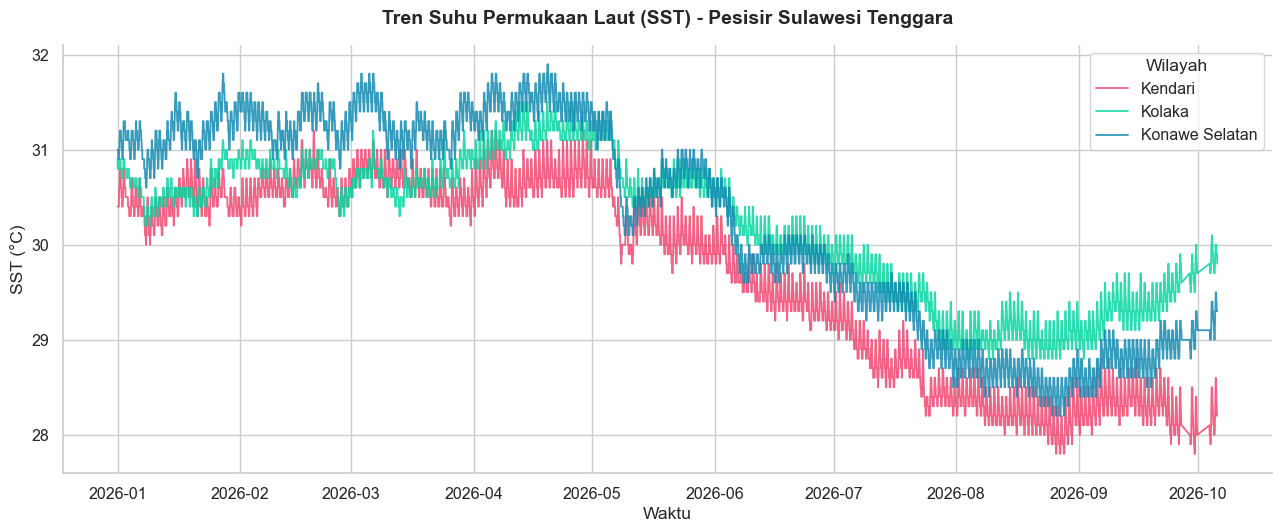

In [32]:
fig, ax = plt.subplots(figsize=(13, 5.5))

for wilayah in df_gabung["wilayah"].unique():
    subset = df_gabung[df_gabung["wilayah"] == wilayah]
    ax.plot(subset["waktu"], subset["sea_surface_temperature"],
            label=wilayah, color=PALET_WILAYAH[wilayah], linewidth=1.3, alpha=0.85)

ax.set_title("Tren Suhu Permukaan Laut (SST) - Pesisir Sulawesi Tenggara", pad=15)
ax.set_xlabel("Waktu")
ax.set_ylabel("SST (°C)")
ax.legend(title="Wilayah", loc="upper right", frameon=True, fancybox=True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

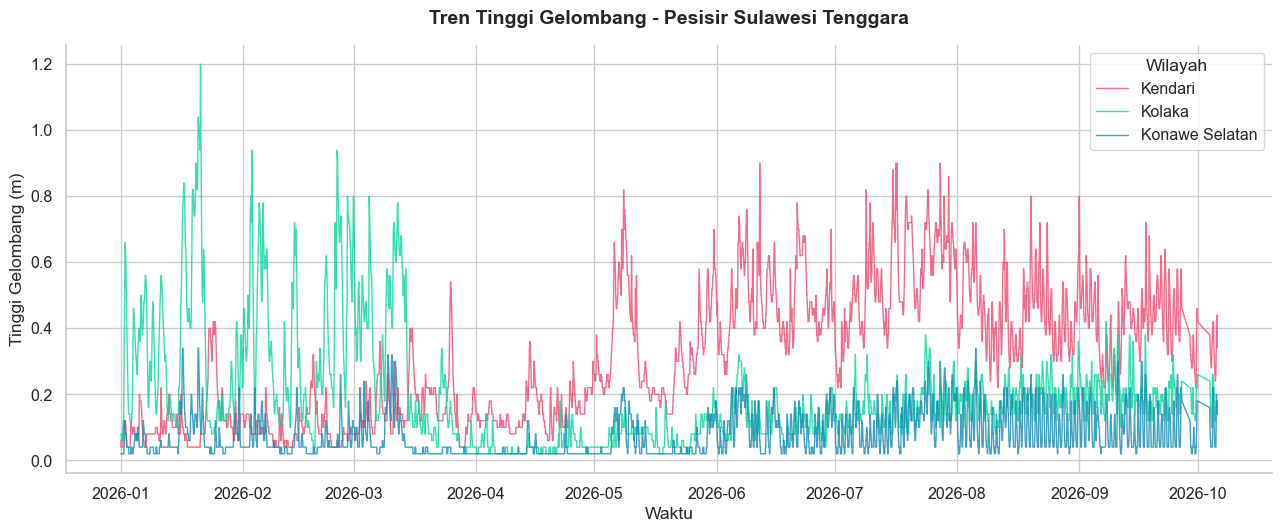

In [33]:
fig, ax = plt.subplots(figsize=(13, 5.5))

for wilayah in df_gabung["wilayah"].unique():
    subset = df_gabung[df_gabung["wilayah"] == wilayah]
    ax.plot(subset["waktu"], subset["wave_height"],
            label=wilayah, color=PALET_WILAYAH[wilayah], linewidth=1, alpha=0.8)

ax.set_title("Tren Tinggi Gelombang - Pesisir Sulawesi Tenggara", pad=15)
ax.set_xlabel("Waktu")
ax.set_ylabel("Tinggi Gelombang (m)")
ax.legend(title="Wilayah", loc="upper right", frameon=True, fancybox=True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

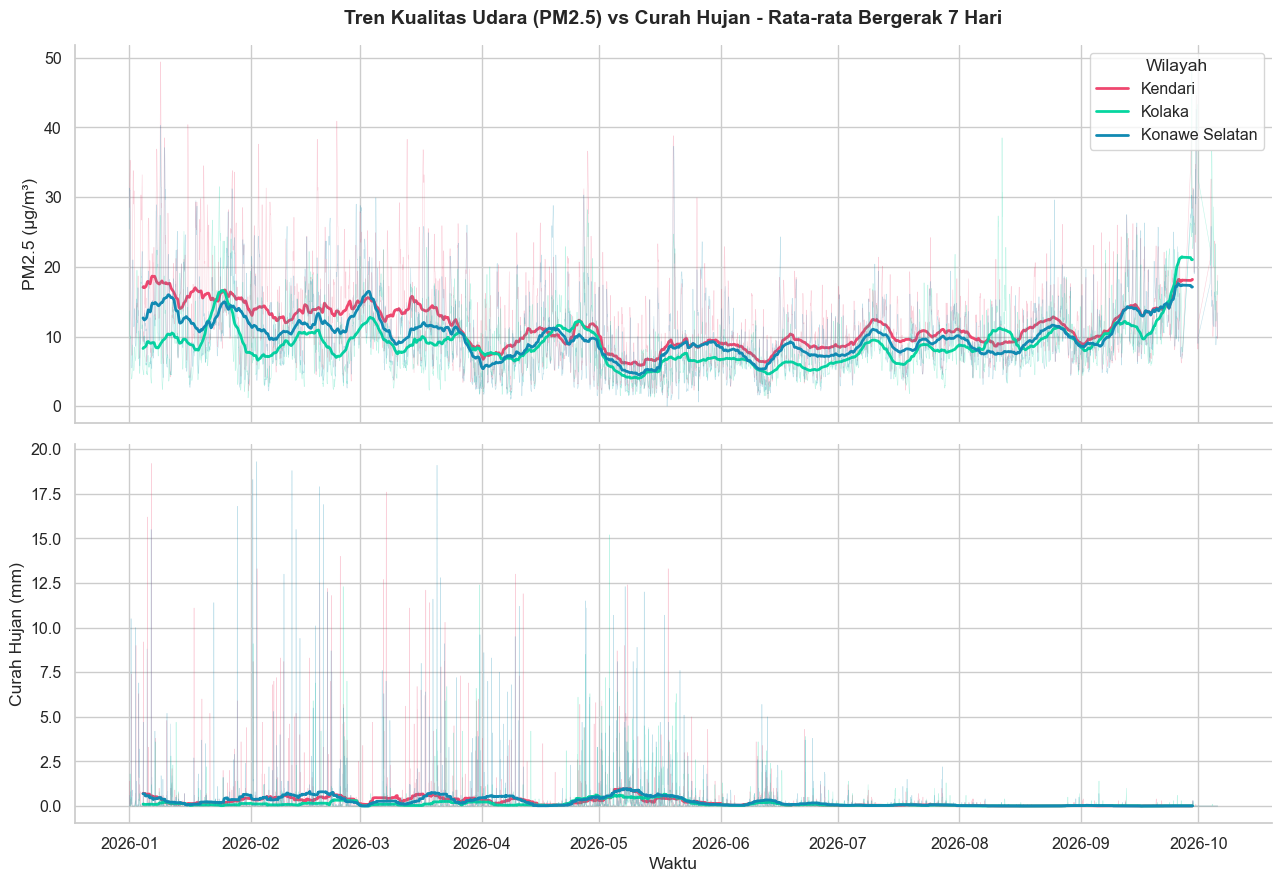

In [35]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for wilayah in df_gabung["wilayah"].unique():
    subset = df_gabung[df_gabung["wilayah"] == wilayah].set_index("waktu")
    warna = PALET_WILAYAH[wilayah]

    # Data mentah - tipis & transparan sebagai konteks
    ax1.plot(subset.index, subset["pm2_5"], color=warna, linewidth=0.4, alpha=0.25)
    ax2.plot(subset.index, subset["precipitation"], color=warna, linewidth=0.4, alpha=0.25)

    # Rolling average 7 hari (168 jam) - garis utama yang jadi fokus
    ax1.plot(subset.index, subset["pm2_5"].rolling(168, center=True).mean(),
              color=warna, linewidth=2, label=wilayah)
    ax2.plot(subset.index, subset["precipitation"].rolling(168, center=True).mean(),
              color=warna, linewidth=2, label=wilayah)

ax1.set_title("Tren Kualitas Udara (PM2.5) vs Curah Hujan - Rata-rata Bergerak 7 Hari", pad=15)
ax1.set_ylabel("PM2.5 (µg/m³)")
ax1.legend(title="Wilayah", loc="upper right", frameon=True)
ax1.spines[["top", "right"]].set_visible(False)

ax2.set_xlabel("Waktu")
ax2.set_ylabel("Curah Hujan (mm)")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Insight:

- Grafik SST menunjukkan tren penurunan bertahap yang jelas dan konsisten di ketiga wilayah, dari sekitar 31°C di Januari menjadi 28°C di September.
- Grafik tinggi gelombang menunjukkan **Kendari secara visual paling sering mengalami gelombang tinggi** (puncak mendekati 1,2m) dibanding Kolaka dan Konawe Selatan, memperkuat temuan Kendari sebagai wilayah dengan risiko lingkungan pesisir tertinggi.
- Grafik PM2.5 (rata-rata bergerak 7 hari) menunjukkan pola yang jelas berkebalikan dengan curah hujan: PM2.5 relatif rendah pada periode curah hujan tinggi (Januari-Juni), kemudian meningkat tajam saat curah hujan mendekati nol (Juli-September), mengonfirmasi fenomena *atmospheric washout* yang telah diidentifikasi sebelumnya.

Pertanyaan 2: Apakah terdapat korelasi signifikan antara anomali SST/gelombang tinggi dengan penurunan kualitas udara di wilayah pesisir?

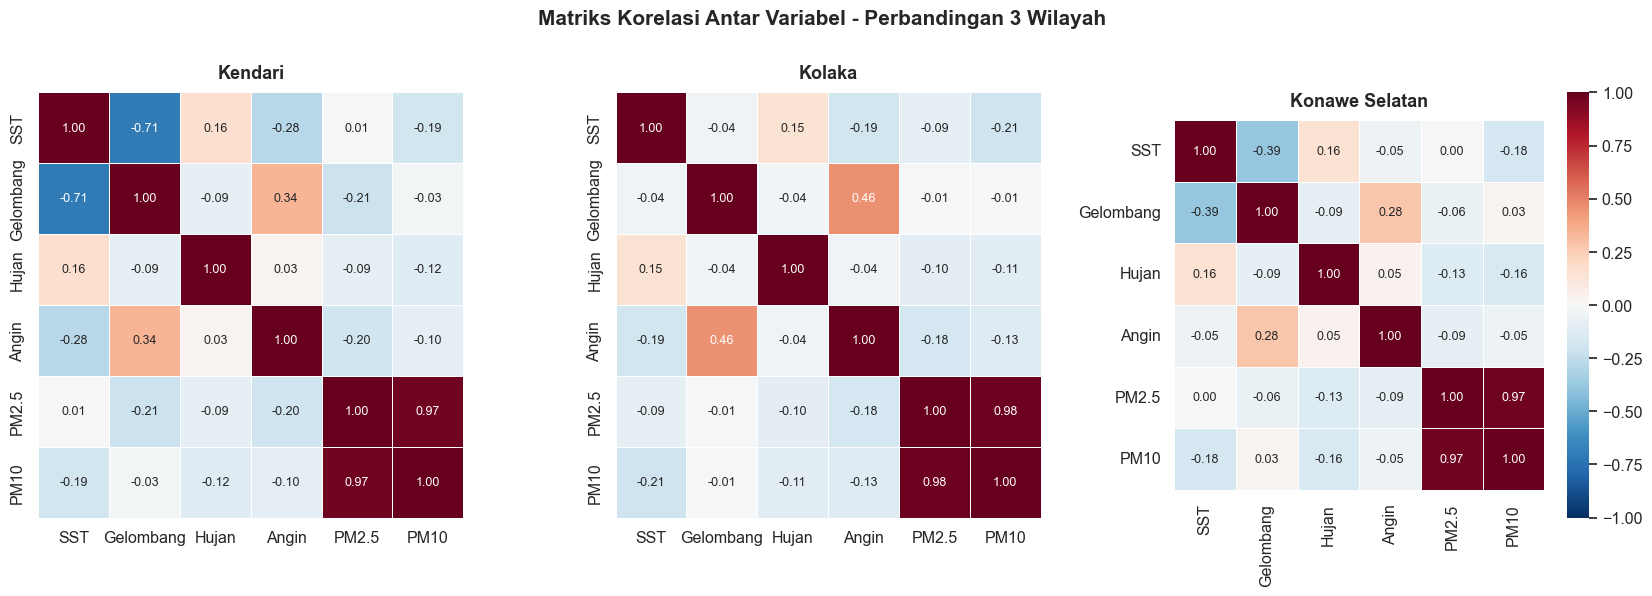

In [36]:
kolom_korelasi = [
    "sea_surface_temperature", "wave_height",
    "precipitation", "windspeed_10m",
    "pm2_5", "pm10",
]

label_rapi = {
    "sea_surface_temperature": "SST",
    "wave_height": "Gelombang",
    "precipitation": "Hujan",
    "windspeed_10m": "Angin",
    "pm2_5": "PM2.5",
    "pm10": "PM10",
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

for ax, wilayah in zip(axes, df_gabung["wilayah"].unique()):
    subset = df_gabung[df_gabung["wilayah"] == wilayah][kolom_korelasi]
    matriks = subset.corr(method="pearson").rename(index=label_rapi, columns=label_rapi)

    sns.heatmap(matriks, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                ax=ax, cbar=(ax == axes[-1]), square=True, linewidths=0.5, linecolor="white",
                annot_kws={"size": 9})
    ax.set_title(wilayah, fontsize=13, fontweight="bold", pad=10)

fig.suptitle("Matriks Korelasi Antar Variabel - Perbandingan 3 Wilayah", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Insight:

- Korelasi antara SST dengan tinggi gelombang menunjukkan variasi signifikan antar wilayah: **Kendari** memiliki korelasi negatif paling kuat (r=-0,71), diikuti **Konawe Selatan** (r=-0,39), sementara **Kolaka** nyaris tidak menunjukkan korelasi (r=-0,04). Variasi ini mengindikasikan karakteristik oseanografi Kendari yang jauh lebih reaktif terhadap perubahan suhu laut dibanding dua wilayah lainnya.
- PM2.5 dan PM10 menunjukkan korelasi sangat tinggi (r=0,97-0,98) secara konsisten di ketiga wilayah sehingga hal yang wajar secara fisik karena keduanya sama-sama partikulat udara yang cenderung bergerak bersamaan.
- Variabel angin (windspeed) menunjukkan korelasi positif dengan tinggi gelombang paling menonjol di Kolaka (r=0,46), dibanding Kendari (r=0,34) dan Konawe Selatan (r=0,28) menunjukkan pengaruh angin terhadap gelombang paling dominan di Kolaka.
- Korelasi antara variabel oseanografi (SST, gelombang) dengan kualitas udara (PM2.5, PM10) secara umum tergolong lemah di seluruh wilayah (r mendekati 0), konsisten dengan hasil uji statistik pada bagian sebelumnya mengonfirmasi bahwa pengaruh kondisi laut terhadap kualitas udara tidak dominan.

Pertanyaan 3: Wilayah mana (Kendari, Kolaka, atau Konawe Selatan) yang memiliki tingkat risiko lingkungan pesisir tertinggi berdasarkan kombinasi ketiga variabel?

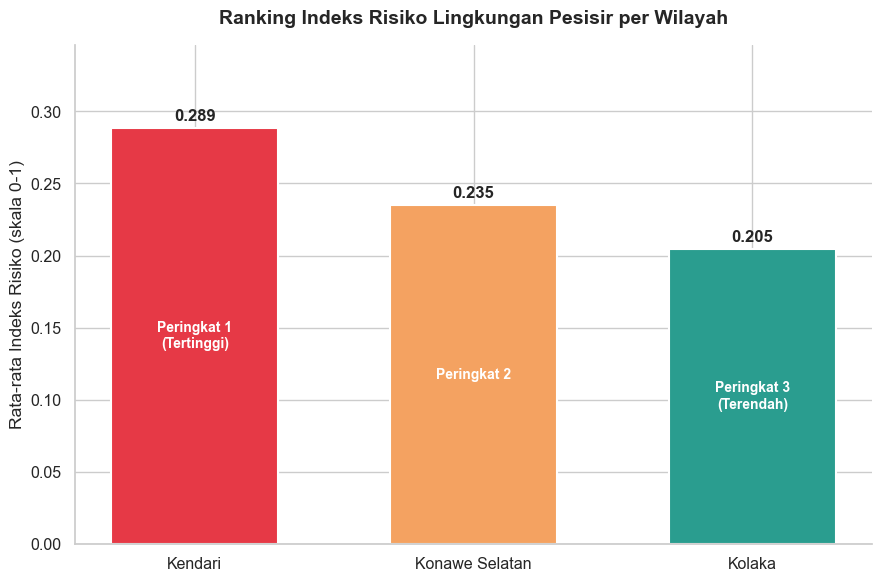

In [37]:
ranking_plot = df_gabung.groupby("wilayah")["indeks_risiko"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))

# Warna gradasi: merah (risiko tertinggi) -> kuning -> hijau (risiko terendah)
warna_ranking = ["#E63946", "#F4A261", "#2A9D8F"]

bars = ax.bar(ranking_plot.index, ranking_plot.values, color=warna_ranking,
              edgecolor="white", linewidth=1.5, width=0.6)

# Anotasi nilai di atas tiap bar
for bar, nilai in zip(bars, ranking_plot.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{nilai:.3f}", ha="center", fontsize=12, fontweight="bold")

# Label peringkat di dalam bar
label_peringkat = ["Peringkat 1\n(Tertinggi)", "Peringkat 2", "Peringkat 3\n(Terendah)"]
for bar, label in zip(bars, label_peringkat):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
            label, ha="center", va="center", fontsize=10, color="white", fontweight="bold")

ax.set_title("Ranking Indeks Risiko Lingkungan Pesisir per Wilayah", pad=15)
ax.set_ylabel("Rata-rata Indeks Risiko (skala 0-1)")
ax.set_ylim(0, max(ranking_plot.values) * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

C:\Users\MyBook PRO K7\AppData\Local\Temp\ipykernel_8348\977124604.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_boxplot, labels=urutan_wilayah, patch_artist=True,


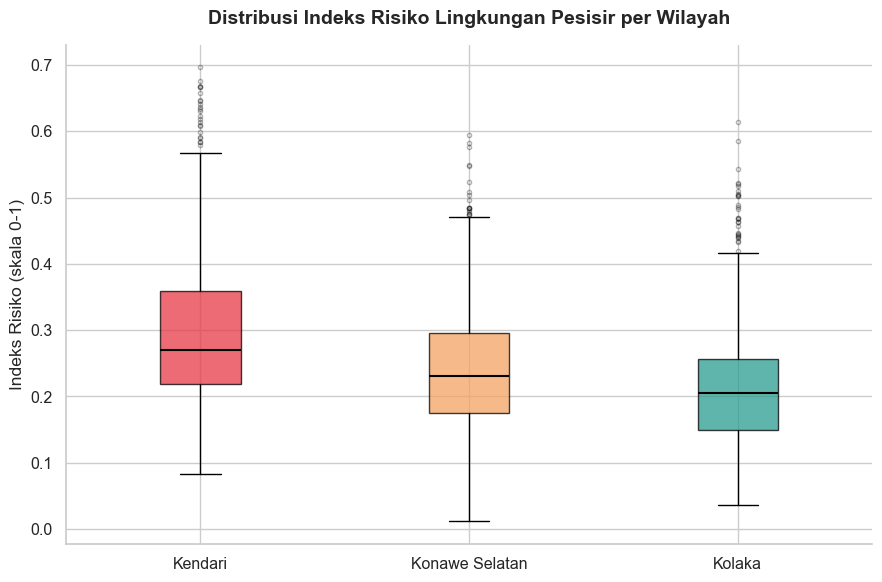

In [38]:
fig, ax = plt.subplots(figsize=(9, 6))

urutan_wilayah = ranking_plot.index.tolist()
data_boxplot = [df_gabung[df_gabung["wilayah"] == w]["indeks_risiko"] for w in urutan_wilayah]

bp = ax.boxplot(data_boxplot, labels=urutan_wilayah, patch_artist=True,
                 medianprops=dict(color="black", linewidth=1.5),
                 flierprops=dict(marker="o", markersize=3, alpha=0.3))

for patch, warna in zip(bp["boxes"], warna_ranking):
    patch.set_facecolor(warna)
    patch.set_alpha(0.75)

ax.set_title("Distribusi Indeks Risiko Lingkungan Pesisir per Wilayah", pad=15)
ax.set_ylabel("Indeks Risiko (skala 0-1)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Insight:

- **Kendari** teridentifikasi sebagai wilayah dengan tingkat risiko lingkungan pesisir **tertinggi** (skor rata-rata 0,289), diikuti Konawe Selatan (0,235) dan Kolaka (0,205) sebagai wilayah dengan risiko terendah.
- Boxplot menunjukkan median risiko Kendari (≈0,27) jauh lebih tinggi dibanding Konawe Selatan (≈0,23) dan Kolaka (≈0,21), dengan rentang interkuartil (kotak) Kendari juga paling lebar mengindikasikan kondisi lingkungan pesisir di Kendari tidak hanya berisiko lebih tinggi secara rata-rata, tetapi juga lebih fluktuatif dan konsisten berada pada level yang lebih tinggi dibanding dua wilayah lainnya.
- Ketiga wilayah menunjukkan outlier (titik-titik di atas whisker) yang menandakan adanya periode-periode dengan kondisi risiko ekstrem, namun jumlah dan sebaran outlier di Kendari tampak lebih signifikan dibanding Kolaka dan Konawe Selatan.
- Temuan ini konsisten dengan hasil analisis korelasi sebelumnya, di mana Kendari juga menunjukkan korelasi SST-gelombang paling kuat (r=-0,71), mengindikasikan karakteristik oseanografi yang lebih reaktif turut berkontribusi terhadap tingginya skor risiko di wilayah ini.

Pertanyaan 4: Bagaimana prediksi kondisi lingkungan pesisir (anomali SST) untuk beberapa hari ke depan menggunakan model machine learning?

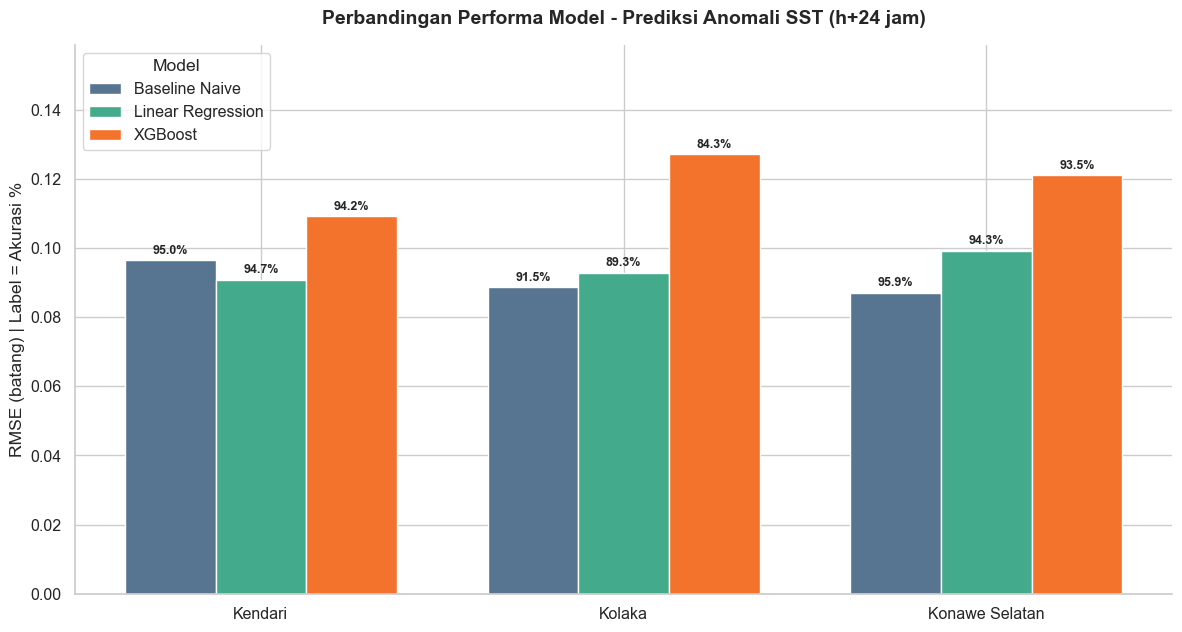

In [41]:
fig, ax = plt.subplots(figsize=(12, 6.5))

x = np.arange(len(df_hasil_model))
lebar = 0.25

# Palet baru - lebih kohesif dan mudah dibedakan
warna_model = {"naive": "#577590", "lr": "#43AA8B", "xgb": "#F3722C"}

bars_naive = ax.bar(x - lebar, df_hasil_model["rmse_naive"], lebar, label="Baseline Naive", color=warna_model["naive"])
bars_lr = ax.bar(x, df_hasil_model["rmse_lr"], lebar, label="Linear Regression", color=warna_model["lr"])
bars_xgb = ax.bar(x + lebar, df_hasil_model["rmse_xgb"], lebar, label="XGBoost", color=warna_model["xgb"])

# Hitung akurasi (100 - MAPE) untuk label persen
akurasi_naive = 100 - df_hasil_model["mape_naive"]
akurasi_lr = 100 - df_hasil_model["mape_lr"]
akurasi_xgb = 100 - df_hasil_model["mape_xgb"]

# Tambahkan label persen akurasi di atas tiap bar
for bars, akurasi in zip([bars_naive, bars_lr, bars_xgb], [akurasi_naive, akurasi_lr, akurasi_xgb]):
    for bar, nilai in zip(bars, akurasi):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f"{nilai:.1f}%", ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(df_hasil_model["wilayah"])
ax.set_ylabel("RMSE (batang) | Label = Akurasi %")
ax.set_title("Perbandingan Performa Model - Prediksi Anomali SST (h+24 jam)", pad=15)
ax.legend(title="Model", frameon=True, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(df_hasil_model["rmse_xgb"]) * 1.25)

plt.tight_layout()
plt.show()

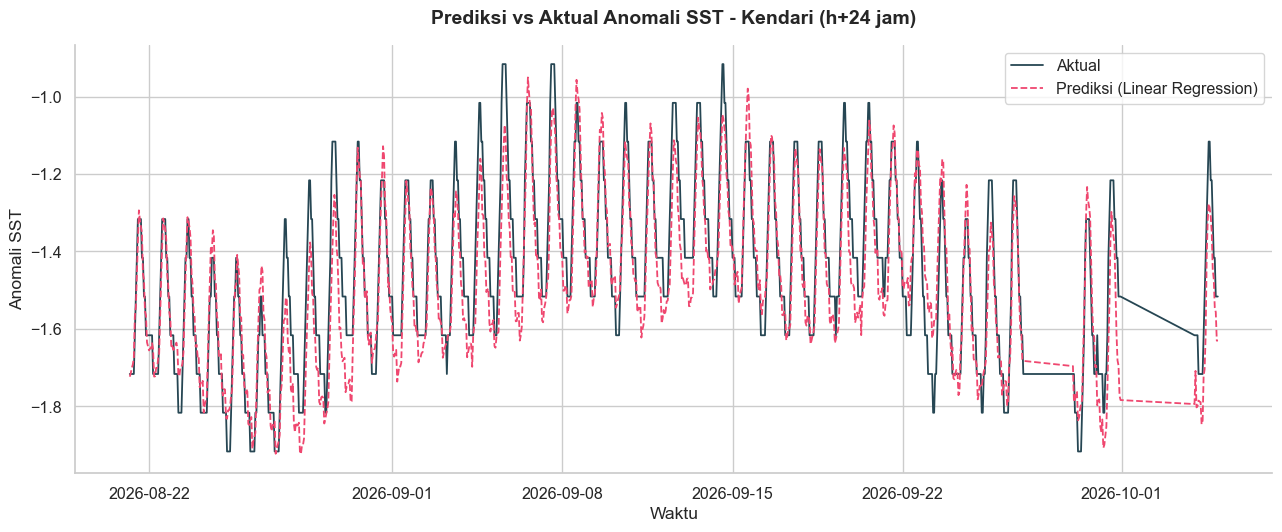

In [42]:
wilayah_fokus = "Kendari"

df_fitur_fokus = df_siap_model[df_siap_model["wilayah"] == wilayah_fokus].sort_values("waktu").reset_index(drop=True)
n = len(df_fitur_fokus)
batas_test = int(n * (1 - RASIO_TEST))
train_fokus, test_fokus = df_fitur_fokus.iloc[:batas_test], df_fitur_fokus.iloc[batas_test:]

X_train_fokus, y_train_fokus = train_fokus[KOLOM_FITUR], train_fokus["target"]
X_test_fokus, y_test_fokus = test_fokus[KOLOM_FITUR], test_fokus["target"]

model_final = LinearRegression().fit(X_train_fokus, y_train_fokus)
prediksi_final = model_final.predict(X_test_fokus)

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(test_fokus["waktu"], y_test_fokus, label="Aktual", color="#264653", linewidth=1.3)
ax.plot(test_fokus["waktu"], prediksi_final, label="Prediksi (Linear Regression)",
        color="#EF476F", linewidth=1.3, linestyle="--")

ax.set_title(f"Prediksi vs Aktual Anomali SST - {wilayah_fokus} (h+24 jam)", pad=15)
ax.set_xlabel("Waktu")
ax.set_ylabel("Anomali SST")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Insight:

- Performa model secara konsisten menunjukkan urutan **Baseline Naive > Linear Regression > XGBoost** di ketiga wilayah, dengan akurasi (100-MAPE) berkisar 84,3%-95,9%.
- **Kolaka** menunjukkan gap performa paling lebar antar model: Baseline Naive mencapai akurasi 91,5%, sementara XGBoost hanya 84,3%  selisih lebih dari 7 poin persen, mengindikasikan XGBoost paling rentan overfitting di wilayah ini.
- Grafik prediksi vs aktual untuk Kendari menunjukkan model mampu mengikuti pola osilasi harian yang teratur dengan cukup baik pada periode Agustus hingga pertengahan September. Namun, akurasi prediksi menurun pada periode akhir pengamatan (akhir September-awal Oktober), ketika pola osilasi aktual melandai dari pola rutinnya  mengindikasikan model mengalami kesulitan beradaptasi terhadap perubahan rezim data yang tidak tercermin dalam data pelatihan.
- Secara keseluruhan, hasil ini menegaskan bahwa untuk variabel dengan tingkat persistensi tinggi seperti anomali SST, model sederhana (persistence atau regresi linear) terbukti menjadi pendekatan yang lebih robust dibandingkan model ensemble yang lebih kompleks, sekaligus menunjukkan bahwa performa model dapat menurun saat menghadapi periode dengan pola yang menyimpang dari kebiasaan historisnya.

## Analisis Lanjutan

Pertanyaan: Apakah terdapat pola variasi dalam jam-jam tertentu sehari yang signifikan pada kadar PM2.5 di wilayah pesisir Sulawesi Tenggara?

In [44]:
# Tambahkan kolom jam ke df_gabung (belum ada sebelumnya di tabel ini)
df_gabung["jam"] = df_gabung["waktu"].dt.hour

pola_jam = df_gabung.groupby(["wilayah", "jam"])["pm2_5"].mean().reset_index()
pola_jam_pivot = pola_jam.pivot(index="jam", columns="wilayah", values="pm2_5")
pola_jam_pivot

wilayah,Kendari,Kolaka,Konawe Selatan
jam,,,
0,14.402930,10.542491,12.085714
1,14.103297,9.784249,11.796703
2,13.838095,9.263004,11.665201
3,13.754212,8.883516,11.713553
4,13.701465,8.568498,11.846886
5,13.807326,8.384615,12.088645
6,14.379853,8.489377,12.806593
7,15.163736,8.993773,13.478388
8,11.441026,9.563004,10.109158


In [45]:
from scipy.stats import f_oneway

print("=== Uji ANOVA: Apakah PM2.5 berbeda signifikan antar jam? ===\n")
for wilayah in df_gabung["wilayah"].unique():
    subset = df_gabung[df_gabung["wilayah"] == wilayah]
    grup_per_jam = [subset[subset["jam"] == j]["pm2_5"].values for j in range(24)]
    f_stat, p_value = f_oneway(*grup_per_jam)
    signifikan = "Signifikan (p<0.05)" if p_value < 0.05 else "Tidak signifikan"
    print(f"{wilayah:20s} | F={f_stat:.3f} | p={p_value:.6f} | {signifikan}")

=== Uji ANOVA: Apakah PM2.5 berbeda signifikan antar jam? ===

Kendari              | F=68.629 | p=0.000000 | Signifikan (p<0.05)
Kolaka               | F=28.060 | p=0.000000 | Signifikan (p<0.05)
Konawe Selatan       | F=52.127 | p=0.000000 | Signifikan (p<0.05)


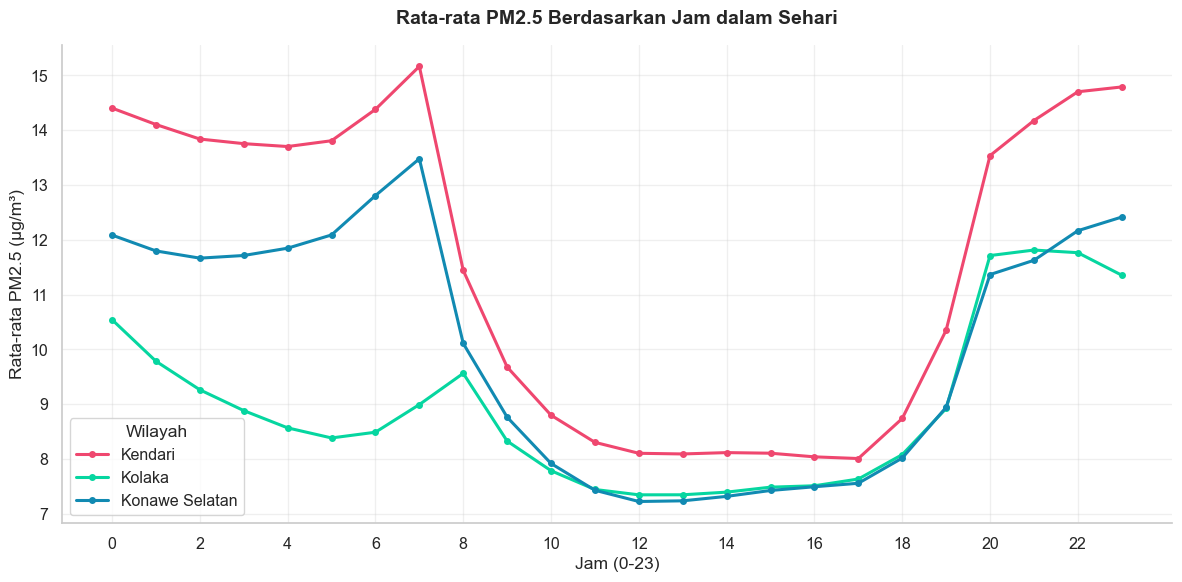

In [46]:
fig, ax = plt.subplots(figsize=(12, 6))

for wilayah in df_gabung["wilayah"].unique():
    ax.plot(pola_jam_pivot.index, pola_jam_pivot[wilayah],
            label=wilayah, color=PALET_WILAYAH[wilayah], linewidth=2.2, marker="o", markersize=4)

ax.set_title("Rata-rata PM2.5 Berdasarkan Jam dalam Sehari", pad=15)
ax.set_xlabel("Jam (0-23)")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="Wilayah", frameon=True)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Insight:

- Uji ANOVA menunjukkan perbedaan kadar PM2.5 antar jam dalam sehari **sangat signifikan secara statistik** di ketiga wilayah (p<0,000001), dengan F-statistik tertinggi di Kendari (F=68,63) dan terendah di Kolaka (F=28,06) mengonfirmasi bahwa pola variasi jam bukan kebetulan, melainkan pola yang nyata dan konsisten.
- Pola harian PM2.5 membentuk kurva **"U-ganda"** yang serupa di ketiga wilayah: kadar tertinggi terjadi pada **dini hari hingga pagi (jam 0-7)**, menurun tajam dan mencapai titik terendah pada **siang-sore hari (jam 9-17)**, kemudian **meningkat tajam kembali mulai malam hari (jam 18-23)**.
- Kendari secara konsisten memiliki kadar PM2.5 tertinggi di hampir semua jam dibanding Kolaka dan Konawe Selatan, sejalan dengan temuan sebelumnya bahwa Kendari merupakan wilayah dengan risiko lingkungan pesisir tertinggi.
- Pola ini secara ilmiah masuk akal dan konsisten dengan fenomena atmosfer yang umum terjadi: pada malam hingga dini hari, lapisan inversi (*temperature inversion*) cenderung terbentuk dan menjebak polutan dekat permukaan tanah, sementara pada siang hari pemanasan matahari meningkatkan percampuran udara vertikal (*atmospheric mixing*) yang membantu menyebarkan dan mengencerkan konsentrasi polutan.
- Temuan analisis tambahan ini memberikan nilai praktis: aktivitas luar ruangan yang sensitif terhadap kualitas udara (seperti olahraga pagi) sebaiknya mempertimbangkan jam-jam dengan kadar PM2.5 lebih rendah (siang hingga sore hari), terutama di wilayah Kendari.

# Conclusion

## Langkah-Langkah yang Telah Dilakukan

1. **Pengambilan Data**: Menarik data secara otomatis dari 3 API (Open-Meteo Marine, Weather, dan Air Quality) menggunakan pipeline ETL berbasis Apache Airflow yang dijadwalkan harian (`@daily`), kemudian disimpan ke 3 tabel MySQL (oseanografi, cuaca, kualitas udara).
2. **Assessing Data**: Menilai kualitas data mencakup struktur, tipe data, missing value, duplikasi, dan rentang nilai pada ketiga tabel tanpa melakukan perubahan apapun.
3. **Cleaning Data**: Melakukan pengurutan data secara kronologis dan menggabungkan (join) ketiga tabel berdasarkan `waktu` dan `wilayah` menjadi satu dataset utuh.
4. **Exploratory Data Analysis (EDA)**: Menganalisis tren suhu permukaan laut, tinggi gelombang, curah hujan, dan kualitas udara di tiga wilayah pesisir Sulawesi Tenggara (Kendari, Kolaka, Konawe Selatan).
5. **Analisis Korelasi**: Menguji hubungan statistik antara anomali SST/tinggi gelombang dengan kualitas udara menggunakan korelasi Pearson.
6. **Perhitungan Indeks Risiko**: Menyusun indeks risiko gabungan dari keempat variabel (anomali SST, gelombang, PM2.5, PM10) untuk menentukan ranking wilayah paling rentan.
7. **Feature Engineering & Modeling**: Membangun fitur lag dan rolling average, kemudian membandingkan 3 model (Baseline Naive, Linear Regression, XGBoost) untuk memprediksi anomali SST 24 jam ke depan.
8. **Analisis Lanjutan**: Menguji pola variasi kadar PM2.5 berdasarkan jam dalam sehari menggunakan uji ANOVA.

## Simpulan Jawaban dari Pertanyaan Bisnis

1. **Tren SST, Gelombang, dan Kualitas Udara**: SST menunjukkan tren penurunan bertahap dari ±31°C (Januari) menjadi ±28°C (September) secara konsisten di ketiga wilayah. Curah hujan menunjukkan pola musiman jelas (tinggi Januari-Juni, rendah Juli-September), sementara PM2.5 menunjukkan pola berkebalikan dengan curah hujan akibat fenomena *atmospheric washout*.

2. **Korelasi Anomali SST/Gelombang dengan Kualitas Udara**: Korelasi yang ditemukan secara umum tergolong lemah namun signifikan secara statistik. Korelasi paling konsisten ditemukan antara anomali SST dengan PM10 (r=-0,17 hingga -0,20) dan antara curah hujan dengan PM2.5 (r=-0,09 hingga -0,13), sementara tinggi gelombang tidak menunjukkan hubungan yang jelas dengan kualitas udara.

3. **Wilayah dengan Risiko Lingkungan Pesisir Tertinggi**: **Kendari** teridentifikasi sebagai wilayah dengan risiko tertinggi (skor rata-rata 0,289), diikuti Konawe Selatan (0,235) dan Kolaka (0,205). Temuan ini konsisten dengan korelasi SST-gelombang yang juga paling kuat di Kendari (r=-0,71).

4. **Prediksi Anomali SST dengan Machine Learning**: Baseline Naive dan Linear Regression secara konsisten mengungguli XGBoost di ketiga wilayah, dengan akurasi berkisar 84,3%-95,9%. Temuan ini mengindikasikan anomali SST memiliki persistensi tinggi, sehingga model sederhana lebih robust dibanding model ensemble yang kompleks untuk kasus ini.

5. **(Analisis Tambahan) Pola PM2.5 Berdasarkan Jam**: Ditemukan pola harian yang sangat signifikan (p<0,000001 di ketiga wilayah) berbentuk kurva U-ganda dan kadar PM2.5 tertinggi pada dini hari-pagi dan malam hari, terendah pada siang-sore hari, konsisten dengan fenomena inversi suhu dan pencampuran udara vertikal.
